# Highlighting important regions with ISM

*In silico* mutagenesis (ISM) mutates every position in a region to each alternative base and scores the predicted effect of each substitution, revealing which bases drive a model's predictions. This tutorial uses ISM with AlphaGenome 2 to identify the bases that drive predicted DNase-seq accessibility across the central 256 bp of a 16 kb sequence window on chr20 in K562 cells (`EFO:0002067`). A 16 kb context keeps the 768 predictions fast; use `dna_client.SEQUENCE_LENGTH_1MB` (1 Mb) for highest accuracy, but at a slower speed.

Key activities:

*   Define a 16 kb context interval and a 256 bp target `ism_interval`
*   Score all 768 single-base substitutions across `ism_interval` with `score_ism_variants`
*   Visualize per-base attribution scores as a sequence logo

Here is a visual overview of this process:

<a href="https://services.google.com/fh/files/misc/ism_green_v2.png"><img src="https://services.google.com/fh/files/misc/ism_green_v2.png" alt="ISM" border="0" height=500></a>

## Set up

In [1]:
# @title Install AlphaGenome

# @markdown Run this cell to install AlphaGenome.
from IPython.display import clear_output
! pip install alphagenome
clear_output()

In [2]:
# @title Imports
from alphagenome import colab_utils
from alphagenome.data import genome
from alphagenome.interpretation import ism
from alphagenome.models.v2 import dna_client
from alphagenome.models.v2 import variant_scorers
from alphagenome.visualization import plot_components
import matplotlib.pyplot as plt

Store your API key in Colab Secrets for persistent access across sessions (see [Installation](https://www.alphagenomedocs.com/installation.html#add-api-key-to-secrets)), then initialize the client:

In [3]:
dna_model = dna_client.create(colab_utils.get_api_key())

## Define the context and ISM intervals

We define an `ism_interval`, which is a relatively small region of DNA that we
want to systematically mutate. We also define the `sequence_interval`, which is
the contextual interval the model will use when making predictions for each
variant:

In [4]:
# 16 kb DNA sequence window used as context when making predictions.
sequence_interval = genome.Interval('chr20', 3_753_000, 3_753_400)
sequence_interval = sequence_interval.resize(dna_client.SEQUENCE_LENGTH_16KB)

# Mutate all bases in the central 256-base region of the sequence_interval.
ism_interval = sequence_interval.resize(256)

## Choose a condition and scorer

Search available reference conditions to retrieve the ontology CURIE for your target cell type or tissue. For more details, see [Choosing a condition](https://www.alphagenomedocs.com/colabs/v2/choosing_a_condition.html).

We examine DNase-seq accessibility predictions in K562 cells (`EFO:0002067`):

In [5]:
# Set condition
target_condition = 'EFO:0002067'  # K562

Next, we define a `CenterMaskScorer` that averages the ALT minus REF `DNASE` difference over a 501 bp window centered on each variant (`DIFF_MEAN`). `variant_scorers.RECOMMENDED_VARIANT_SCORERS['DNASE']` uses the same 501 bp window with `DIFF_LOG2_SUM` and works here too; see [How variant scoring works](https://www.alphagenomedocs.com/variant_scoring.html).

In [6]:
dnase_variant_scorer = variant_scorers.CenterMaskScorer(
    requested_output=dna_client.OutputType.DNASE,
    width=501,
    aggregation_type=variant_scorers.AggregationType.DIFF_MEAN,
)

## Score all substitutions

Call `dna_model.score_ism_variants` to score every single-base substitution in `ism_interval` (the client splits the window into 10 bp requests and evaluates them in parallel):

In [7]:
variant_scores = dna_model.score_ism_variants(
    interval=sequence_interval,
    ism_interval=ism_interval,
    variant_scorers=[dnase_variant_scorer],
    condition=target_condition,  # K562.
)

  0%|          | 0/26 [00:00<?, ?it/s]

The length of the returned `variant_scores` is 768, since we scored 768 variants
(256 positions * 3 alternate bases per position):

In [8]:
len(variant_scores)

768

Each variant has scores of shape `(1, 2)`, reflecting a non-gene-centric scorer across the 2 `DNASE` tracks for K562:

In [9]:
# Index into first variant and first scorer.
variant_scores[0][0].X.shape

(1, 2)

## Select the paired-end track

We have two tracks (for single-ended and paired-ended predictions). We select the paired-end track:

In [10]:
def extract_paired_end(adata):
  values = adata.X[
      :,
      (adata.var['endedness'] == 'paired'),
  ]
  assert values.size == 1
  return values.flatten()[0]


ism_result = ism.ism_matrix(
    [extract_paired_end(x[0]) for x in variant_scores],
    variants=[v[0].uns['variant'] for v in variant_scores],
)

`ism.ism_matrix()` defaults to `multiply_by_sequence=True`, so the output array retains non-zero contribution values only at the reference sequence base at each position.

The shape of `ism_result` is `(256, 4)` since we have 1 score per position for each of the 4 DNA bases:

In [11]:
ism_result.shape

(256, 4)

## Plot a sequence logo

To understand which positions most strongly influence predicted accessibility, we visualize the attribution matrix with `plot_components.SeqLogo`. Each variant was already reduced to a single scalar (the paired-end `DNASE` score) by `extract_paired_end`, and `ism.ism_matrix` arranged these values into a `(position, base)` matrix:

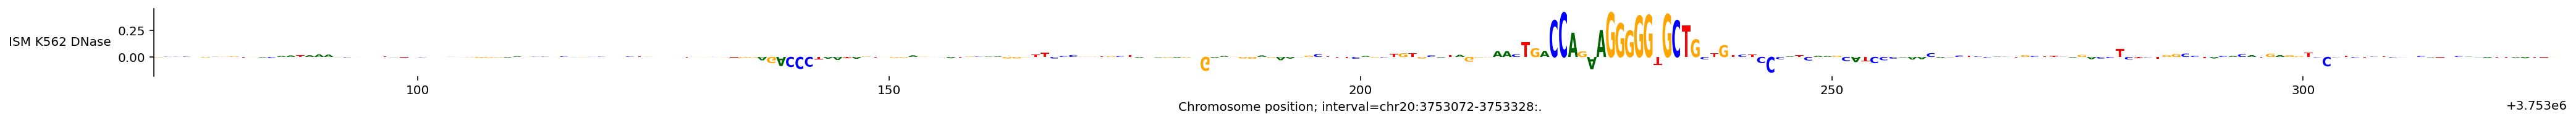

In [12]:
plot_components.plot(
    [
        plot_components.SeqLogo(
            scores=ism_result,
            scores_interval=ism_interval,
            ylabel='ISM K562 DNase',
        )
    ],
    interval=ism_interval,
    fig_width=35,
)

plt.show()

This plot shows that bases between positions ~225 and ~240 have the strongest
effect on predicted nearby DNase-seq accessibility in K562 cells.

These contribution scores can be used to systematically discover motifs
important for different modalities and cell types, identify candidate binding
factors, and map motif instances across the genome. Common downstream motif
tools include:

*   [tfmodisco-lite](https://github.com/jmschrei/tfmodisco-lite/)
*   [tangermeme](https://github.com/jmschrei/tangermeme)
*   [tomtom](https://meme-suite.org/meme/tools/tomtom)